# Notebook 2 — Vector RAG
## PharmaGraph-OTC: Answering Drug-Safety Questions over Over-the-Counter Medicines — GraphRAG vs Vector RAG
**AIML506 · Course Assignment** · Dataset: *Pharma-safe Index Dataset* (Sebastian, Restyandito & Nugroho; Mendeley Data, DOI **10.17632/m78j7ctwhn.2**; data article DOI 10.1016/j.dib.2024.110794).

**What this notebook does (Task 4):** record serialisation → embeddings → ChromaDB → similarity search → LLM answer generation, plus **evaluated** options:
hybrid BM25 + dense retrieval and a finer-grained "fact-level" chunking.

**Inputs:** add the *output of Notebook 1* as a Kaggle input (`drug_records.json`, `schema_note.txt`). Internet on, GPU on.
**Outputs:** `vector_rag.py`, `rag_common.py`, `chroma_db/`, `build_costs_vector.json`, `topk_sweep.csv`, `embedding_ablation.csv`.

*Same data, same generator, same prompt as Notebook 1 — only retrieval differs.*

In [1]:
!pip -q install chromadb sentence-transformers rank_bm25 2>&1 | tail -1
import os, re, json, time, random, glob, shutil, warnings, hashlib
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = "/kaggle/working"; os.makedirs(OUT, exist_ok=True); os.chdir(OUT); os.makedirs(f"{OUT}/figures", exist_ok=True)

# ---------------- configuration ----------------
EMB_MODEL         = "BAAI/bge-small-en-v1.5"      # 384-d, 33M parameters
COMPARE_EMBEDDERS = ["sentence-transformers/all-MiniLM-L6-v2", "BAAI/bge-base-en-v1.5"]    # ablation in Section 6 ([] to skip)
K_EVAL, K_CONTEXT = 5, 10                          # metrics @5; up to 10 items go to the generator (same budget as GraphRAG)
GEN_MODEL         = "qwen2.5:7b-instruct"          # SAME generator as notebook 1
PERSIST_DIR       = f"{OUT}/chroma_db"
BUILD = {}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", DEVICE)

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"{OUT}/{name}")
    assert hits, f"{name} not found - add the output of notebook 1 as an input."
    return hits[0]

google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
device: cuda


## 0. Pipeline code written to disk
`rag_common.py` is **byte-identical** to the copy in Notebook 1 (one prompt, one schema, one serialiser for both systems). `vector_rag.py` holds the indexing and retrieval code (read it in Section 2).

In [2]:
%%writefile rag_common.py
"""Shared helpers for both RAG systems: Ollama client, ONE prompt template,
answer schema and row serialisation.  Keep this file identical in all notebooks:
the fairness of the GraphRAG vs Vector RAG comparison depends on it."""
import json
import os
import re
import subprocess
import time

import requests

OLLAMA_URL = os.environ.get("OLLAMA_URL", "http://127.0.0.1:11434")
GEN_OPTIONS = {"temperature": 0.0, "seed": 42, "num_ctx": 8192, "num_predict": 400}
MAX_CONTEXT_CHARS = 8000          # same context budget for every system

SCHEMA_NOTE = (
    "The database covers 112 over-the-counter drugs sold in pharmacies in Yogyakarta, Indonesia. For each drug it holds only: "
    "name, disease category, indication, composition (ingredients with amounts), side effects, contraindications, "
    "drug interactions, dose (adult / children), usage rules, period of use and price per unit. "
    "It does NOT hold manufacturers, mechanisms of action, storage or shelf life, regulatory approval, clinical evidence, "
    "prescription-only drugs, or any drug that is not one of these products."
)


def set_schema_note(text):
    global SCHEMA_NOTE
    SCHEMA_NOTE = text


SYSTEM_PROMPT = """You are a careful assistant for questions about over-the-counter drugs in a small pharmacy database.
Answer ONLY from the numbered EVIDENCE items you are given.
Rules:
1. Never use outside knowledge. If the evidence does not contain the answer, set "answerable" to false and
   set "answer" to "The available data does not contain this information."
2. Cite the ids of the evidence items you used (for example G1 or V3) in "citations".
3. Be concise. List every item the question asks for. For counts, use the number stated in the evidence.
4. Do not give medical advice.
Reply with JSON only: {"answerable": true|false, "answer": "...", "citations": ["G1", ...]}"""

ANSWER_SCHEMA = {
    "type": "object",
    "properties": {
        "answerable": {"type": "boolean"},
        "answer": {"type": "string"},
        "citations": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["answerable", "answer", "citations"],
}

REFUSAL_RE = re.compile(
    r"(does not contain|do not contain|cannot (be )?answer|not (available|contained|included|provided|in the (data|evidence))"
    r"|no (information|evidence|data)|insufficient)", re.I)


# ----------------------------------------------------------------------------- Ollama
def ollama_up():
    try:
        return requests.get(OLLAMA_URL, timeout=2).status_code == 200
    except Exception:
        return False


def ensure_ollama(wait=90):
    """Start `ollama serve` in the background if it is not running."""
    if ollama_up():
        return True
    log = open("/kaggle/working/ollama.log" if os.path.isdir("/kaggle/working") else "ollama.log", "w")
    subprocess.Popen(["ollama", "serve"], stdout=log, stderr=log)
    for _ in range(wait):
        if ollama_up():
            return True
        time.sleep(1)
    raise RuntimeError("Ollama server did not start - check ollama.log")


def pull(model):
    subprocess.run(["ollama", "pull", model], check=True)


def chat(model, system, user, schema=None, options=None, timeout=600):
    """One chat call. Returns text + latency + token counts."""
    opts = dict(GEN_OPTIONS)
    opts.update(options or {})
    payload = {"model": model, "stream": False, "options": opts,
               "messages": [{"role": "system", "content": system}, {"role": "user", "content": user}]}
    if schema is not None:
        payload["format"] = schema
    t0 = time.perf_counter()
    r = requests.post(f"{OLLAMA_URL}/api/chat", json=payload, timeout=timeout)
    r.raise_for_status()
    d = r.json()
    return {"text": d["message"]["content"], "latency_s": time.perf_counter() - t0,
            "prompt_tokens": d.get("prompt_eval_count"), "output_tokens": d.get("eval_count")}


# ----------------------------------------------------------------------------- prompt
def build_user_prompt(question, items, max_chars=None):
    """Numbered evidence block under a fixed character budget. Returns (prompt, ids_kept)."""
    max_chars = max_chars or MAX_CONTEXT_CHARS
    lines, kept, used = [], [], 0
    for it in items:
        line = f"[{it['id']}] {it['text']}"
        if used + len(line) + 1 > max_chars:
            break
        lines.append(line)
        kept.append(it["id"])
        used += len(line) + 1
    evidence = "\n".join(lines) if lines else "(no evidence retrieved)"
    prompt = f"DATA SCOPE: {SCHEMA_NOTE}\n\nEVIDENCE:\n{evidence}\n\nQUESTION: {question}"
    return prompt, kept


def parse_answer(text):
    try:
        d = json.loads(text)
    except Exception:
        m = re.search(r"\{.*\}", text, re.S)
        try:
            d = json.loads(m.group(0)) if m else None
        except Exception:
            d = None
    if not isinstance(d, dict) or "answer" not in d:
        return {"answerable": not bool(REFUSAL_RE.search(text)), "answer": text.strip(),
                "citations": re.findall(r"\b[GV]\d+\b", text), "parse_ok": False}
    cits = d.get("citations") or []
    if not isinstance(cits, list):
        cits = [str(cits)]
    return {"answerable": bool(d.get("answerable", True)), "answer": str(d.get("answer", "")).strip(),
            "citations": [str(c).strip("[] ") for c in cits], "parse_ok": True}


def generate_answer(model, question, items, options=None):
    """The SAME generator call for every retrieval system."""
    prompt, kept = build_user_prompt(question, items)
    out = chat(model, SYSTEM_PROMPT, prompt, schema=ANSWER_SCHEMA, options=options)
    res = parse_answer(out["text"])
    res.update({"raw": out["text"], "gen_latency_s": out["latency_s"], "prompt_tokens": out["prompt_tokens"],
                "output_tokens": out["output_tokens"], "kept_ids": kept, "prompt_chars": len(prompt)})
    return res


# ----------------------------------------------------------------------------- data helpers
def _j(items, sep="; "):
    return sep.join(str(x) for x in items if str(x).strip())


def serialize_drug(rec):
    """One drug record -> one text document (all linked tables joined through the drug id)."""
    parts = [f"Drug: {rec['name']}", f"Disease category: {rec['category']}"]
    if rec.get("indication"):
        parts.append(f"Indication: {rec['indication']}")
    if rec.get("ingredients"):
        parts.append("Composition: " + _j(rec["ingredients"]))
    if rec.get("side_effects"):
        parts.append("Side effects: " + _j(rec["side_effects"]))
    if rec.get("contraindications"):
        parts.append("Contraindications: " + _j(rec["contraindications"]))
    if rec.get("interactions"):
        parts.append("Drug interactions: " + _j(rec["interactions"]))
    dose = [f"{k}: {rec[f'dose_{k}']}" for k in ("adult", "children", "other") if rec.get(f"dose_{k}")]
    if dose:
        parts.append("Dose - " + _j(dose))
    if rec.get("usage_rules"):
        parts.append("Usage rules: " + _j(rec["usage_rules"]))
    if rec.get("usage_period"):
        parts.append("Period of use: " + str(rec["usage_period"]))
    if rec.get("prices"):
        parts.append("Price: " + _j(f"{u} IDR {p}" for u, p in rec["prices"]))
    return ". ".join(p.rstrip(". ") for p in parts) + "."


def fact_chunks(rec):
    """Finer-grained chunks: one per aspect, each prefixed with the drug name. Returns [(aspect, text)]."""
    n = rec["name"]
    out = [("category", f"Drug: {n}. Disease category: {rec['category']}. Indication: {rec.get('indication', '')}")]
    if rec.get("ingredients"):
        out.append(("composition", f"Drug: {n}. Composition: {_j(rec['ingredients'])}"))
    if rec.get("side_effects"):
        out.append(("side_effects", f"Drug: {n}. Side effects: {_j(rec['side_effects'])}"))
    if rec.get("contraindications"):
        out.append(("contraindications", f"Drug: {n}. Contraindications: {_j(rec['contraindications'])}"))
    if rec.get("interactions"):
        out.append(("interactions", f"Drug: {n}. Drug interactions: {_j(rec['interactions'])}"))
    dose = [f"{k}: {rec[f'dose_{k}']}" for k in ("adult", "children", "other") if rec.get(f"dose_{k}")]
    use = (["Dose - " + _j(dose)] if dose else []) + (["Usage rules: " + _j(rec["usage_rules"])] if rec.get("usage_rules") else []) + \
          ([f"Period of use: {rec['usage_period']}"] if rec.get("usage_period") else [])
    if use:
        out.append(("usage", f"Drug: {n}. " + ". ".join(use)))
    if rec.get("prices"):
        out.append(("price", f"Drug: {n}. Price: " + _j(f"{u} IDR {p}" for u, p in rec["prices"])))
    return [(a, t.rstrip(".") + ".") for a, t in out]


def load_records(path):
    """drug_records.json written by notebook 1."""
    with open(path) as f:
        recs = json.load(f)
    for r in recs:
        r["prices"] = [tuple(x) for x in r.get("prices", [])]
    return recs

Writing rag_common.py


In [3]:
%%writefile vector_rag.py
"""Vector RAG over the same drug records: record-level and fact-level indexes in ChromaDB,
dense retrieval (bge-small, cosine) and hybrid BM25 + dense retrieval with reciprocal rank fusion."""
import json
import re
import time
from collections import defaultdict

import chromadb
from rank_bm25 import BM25Okapi

import rag_common as rc

EMB_MODEL = "BAAI/bge-small-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "


def tokenize(s):
    return re.findall(r"[a-z0-9]+", s.lower())


# ----------------------------------------------------------------------------- documents
def build_record_docs(recs):
    """Main index: ONE CHUNK PER DRUG. The nine linked CSV tables are joined through the drug id and serialised
    into one text record (~200-350 tokens, well inside the embedder's 512-token limit)."""
    ids, docs, metas = [], [], []
    for r in recs:
        ids.append(f"d{r['id']}")
        docs.append(rc.serialize_drug(r))
        metas.append({"rid": int(r["id"]), "row_ids": json.dumps([int(r["id"])]), "kind": "record"})
    return ids, docs, metas


def build_fact_docs(recs):
    """Variant index: one chunk per aspect of a drug (category, composition, side effects, ...), each prefixed with the drug name."""
    ids, docs, metas = [], [], []
    for r in recs:
        for aspect, text in rc.fact_chunks(r):
            ids.append(f"d{r['id']}::{aspect}")
            docs.append(text)
            metas.append({"rid": int(r["id"]), "row_ids": json.dumps([int(r["id"])]), "kind": aspect})
    return ids, docs, metas


# ----------------------------------------------------------------------------- indexing
def build_collection(client, name, ids, docs, metas, embedder, batch=512):
    try:
        client.delete_collection(name)
    except Exception:
        pass
    col = client.create_collection(name, metadata={"hnsw:space": "cosine"})
    t0 = time.perf_counter()
    for i in range(0, len(docs), batch):
        emb = embedder.encode(docs[i:i + batch], normalize_embeddings=True, batch_size=64,
                              show_progress_bar=False).tolist()
        col.add(ids=ids[i:i + batch], documents=docs[i:i + batch], embeddings=emb, metadatas=metas[i:i + batch])
    return col, time.perf_counter() - t0


# ----------------------------------------------------------------------------- retrieval
class VectorRetriever:
    def __init__(self, persist_dir, collection_name, embedder):
        self.client = chromadb.PersistentClient(path=persist_dir)
        self.col = self.client.get_collection(collection_name)
        self.embedder = embedder
        self._bm25 = None
        self._corpus = None

    # lazily built BM25 index over the same chunks
    def _ensure_bm25(self):
        if self._bm25 is None:
            got = self.col.get(include=["documents", "metadatas"])
            self._corpus = {"ids": got["ids"], "docs": got["documents"], "metas": got["metadatas"]}
            self._bm25 = BM25Okapi([tokenize(d) for d in got["documents"]])

    def _embed_query(self, q):
        return self.embedder.encode([QUERY_PREFIX + q], normalize_embeddings=True)[0].tolist()

    def dense(self, q, n):
        res = self.col.query(query_embeddings=[self._embed_query(q)], n_results=n,
                             include=["documents", "metadatas", "distances"])
        return [(i, d, m, 1.0 - dist) for i, d, m, dist in
                zip(res["ids"][0], res["documents"][0], res["metadatas"][0], res["distances"][0])]

    def bm25(self, q, n):
        self._ensure_bm25()
        scores = self._bm25.get_scores(tokenize(q))
        top = sorted(range(len(scores)), key=lambda i: -scores[i])[:n]
        c = self._corpus
        return [(c["ids"][i], c["docs"][i], c["metas"][i], float(scores[i])) for i in top if scores[i] > 0]

    def hybrid(self, q, n, pool=50, rrf_k=60):
        fused, store = defaultdict(float), {}
        for ranked in (self.dense(q, pool), self.bm25(q, pool)):
            for rank, (i, d, m, s) in enumerate(ranked, start=1):
                fused[i] += 1.0 / (rrf_k + rank)
                store[i] = (d, m)
        order = sorted(fused, key=lambda i: -fused[i])[:n]
        return [(i, store[i][0], store[i][1], fused[i]) for i in order]

    def retrieve(self, question, k=10, mode="dense"):
        t0 = time.perf_counter()
        hits = self.dense(question, k) if mode == "dense" else self.hybrid(question, k)
        items = []
        for rank, (i, d, m, s) in enumerate(hits, start=1):
            items.append({"id": f"V{rank}", "text": d, "row_ids": json.loads(m.get("row_ids", "[]")),
                          "score": round(float(s), 4), "kind": m.get("kind", "row")})
        return {"items": items, "mode": mode, "retrieval_latency_s": time.perf_counter() - t0, "links": [], "n_records": len(items)}

Writing vector_rag.py


## Task 4 — Design choices and justification

| Choice | Decision | Why |
|---|---|---|
| **Store** | **ChromaDB** (persistent, local) | As in the lab; no infrastructure. The corpus is tiny (112 records, a few hundred fact chunks), so FAISS/Qdrant/Milvus add complexity but no accuracy |
| **Serialisation / chunking (main)** | **One chunk per drug**: the nine linked CSV tables are joined on the drug id and written as one text record (`Drug: … Disease category: … Composition: … Side effects: … Contraindications: … Price: …`) | A drug record is one coherent unit (~150-350 tokens, inside the embedder's 512-token limit). Splitting would separate a statement from the drug it belongs to |
| **Chunking (variant)** | **One chunk per aspect** (category, composition, side effects, …), each prefixed with the drug name | Smaller, more precise chunks; the price is ~7× more chunks competing for the top-k |
| **Embedding model** | `BAAI/bge-small-en-v1.5` | Small and fast; query-instruction prefix as recommended. Compared with MiniLM and bge-base in Section 6 |
| **Similarity metric** | **Cosine** on L2-normalised vectors | The models are trained for cosine similarity |
| **Top-k** | Metrics @ **k = 5**; up to **10** items are passed to the generator under the shared character budget | k=5 is the assignment default; Section 6 measures where more context helps |
| **Optional improvement** | **Hybrid BM25 + dense** with reciprocal-rank fusion | Drug names like "Fluzol Tablet4" are rare tokens that lexical search matches exactly |

**Hypothesis for Notebook 3:** counting, ranking and "all drugs that …" questions need *every* matching record; vector search only returns the top-k, and with 112 records top-10 is already ~9% of the corpus.

In [4]:
# ---- load the drug records from notebook 1 --------------------------------------------------------------------------------------
import rag_common as rc, vector_rag as vr
recs = rc.load_records(find("drug_records.json"))
note_path = glob.glob("/kaggle/input/**/schema_note.txt", recursive=True)
if note_path: rc.set_schema_note(open(note_path[0]).read()); print("schema note loaded")
print(len(recs), "drug records")
print(rc.serialize_drug(recs[0]))

schema note loaded
112 drug records
Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gastric acid with symptoms such as nausea, bloating. Composition: Aluminum Hydroxide 200 mg; Magnesium Hydroxide 200 mg. Side effects: sometimes constipation, diarrhea; Nauseous vomit; Hypophosphatemia osteomalacia (on long-term administration of large doses when phosphate levels are low); Dialysis dementia in long-term administration in dialysis patients. Contraindications: Severe kidney dysfunction; hypersensitive; digestive tract obstruction; very weak patient. Drug interactions: Aluminum hydroxide will reduce the absorption of various vitamins and Tetracyclin. Dose - adult: 1-2 tablets, 3-4 times per day.; children: 0.5-1 tablet, 3-4 times per day. Usage rules: Best given on an empty stomach; Give 1-2 hours after eating before bed; Chew the tablet well before swallowing. Period of use: Do not use for 2 weeks. Pr

In [5]:
# ---- serialisation statistics (justifies one-record chunks) -------------------------------------------------------------------------------------------
words = pd.Series([len(rc.serialize_drug(r).split()) for r in recs])
fact_words = pd.Series([len(t.split()) for r in recs for _, t in rc.fact_chunks(r)])
print(f"record chunks: n={len(words)}, words mean {words.mean():.0f}, p95 {words.quantile(.95):.0f}, max {words.max()}  (embedder limit ~512 tokens)")
print(f"fact chunks  : n={len(fact_words)}, words mean {fact_words.mean():.0f}, max {fact_words.max()}")
for aspect, t in rc.fact_chunks(recs[0])[:3]: print(f"  [{aspect}] {t[:160]}")

record chunks: n=112, words mean 194, p95 303, max 494  (embedder limit ~512 tokens)
fact chunks  : n=763, words mean 31, max 209
  [category] Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gastric acid with sympt
  [composition] Drug: Antasida Doen Tablet Kunyah. Composition: Aluminum Hydroxide 200 mg; Magnesium Hydroxide 200 mg.
  [side_effects] Drug: Antasida Doen Tablet Kunyah. Side effects: sometimes constipation, diarrhea; Nauseous vomit; Hypophosphatemia osteomalacia (on long-term administration of


In [6]:
# ---- embedder + indexes (timed) ------------------------------------------------------------------------------------------------------------------------------------
from sentence_transformers import SentenceTransformer
import chromadb
embedder = SentenceTransformer(EMB_MODEL, device=DEVICE)
shutil.rmtree(PERSIST_DIR, ignore_errors=True)
client = chromadb.PersistentClient(path=PERSIST_DIR)
ids, docs, metas = vr.build_record_docs(recs); col_rec, t_rec = vr.build_collection(client, "drug_record", ids, docs, metas, embedder)
ids, docs, metas = vr.build_fact_docs(recs);   col_fact, t_fact = vr.build_collection(client, "drug_fact", ids, docs, metas, embedder)
BUILD.update(embedding_model=EMB_MODEL, index_record_s=round(t_rec, 2), n_record_chunks=col_rec.count(), index_fact_s=round(t_fact, 2), n_fact_chunks=col_fact.count())
print(BUILD)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'embedding_model': 'BAAI/bge-small-en-v1.5', 'index_record_s': 2.12, 'n_record_chunks': 112, 'index_fact_s': 1.74, 'n_fact_chunks': 763}


In [7]:
# ---- similarity search demo -------------------------------------------------------------------------------------------------------------------------------------------
Rrec  = vr.VectorRetriever(PERSIST_DIR, "drug_record", embedder)
Rfact = vr.VectorRetriever(PERSIST_DIR, "drug_fact", embedder)
r0 = next(r for r in recs if r["effect_terms"] and r["contra_terms"])
top_eff = Counter(t for r in recs for t in r["effect_terms"]).most_common(1)[0][0]
top_ing = Counter(n for r in recs for n in r["ingredient_names"]).most_common(1)[0][0]

def show(question, retr, mode="dense", n=4):
    r = retr.retrieve(question, k=n, mode=mode)
    print(f"[{mode}] {question}   ({r['retrieval_latency_s']*1000:.0f} ms)")
    for it in r["items"]: print(f"   [{it['id']}] score={it['score']:.3f}  {it['text'][:150]}")
    print()
show(f"What is the price of '{r0['name']}' per {r0['prices'][0][0]}?", Rrec)
show(f"Which drugs list {top_eff} as a side effect?", Rrec)
show(f"How many drugs contain {top_ing}?", Rrec)

[dense] What is the price of 'Antasida Doen Tablet Kunyah' per strip?   (49 ms)
   [V1] score=0.714  Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gastric acid 
   [V2] score=0.641  Drug: Dexanta Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, duodenal ulcer
   [V3] score=0.633  Drug: Gastrucid Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, duodenal ulc
   [V4] score=0.623  Drug: Promag Tablet Kunyah. Disease category: stomach. Indication: Relieve symptoms associated with excess gastric acid, gastritis, gastric ulcers, du

[dense] Which drugs list dry mouth as a side effect?   (13 ms)
   [V1] score=0.682  Drug: Decolgen Kids Flu. Disease category: flu. Indication: To relieve flu symptoms such as fever, headache, sneezing and nasal congestion. Side ef

In [8]:
# ---- dense vs hybrid on an exact drug-name query, and the fact-level index --------------------------------------------------------------------------------------
qn = f"What precautions apply to '{r0['name']}'?"
show(qn, Rrec, "dense", 3); show(qn, Rrec, "hybrid", 3); show(qn, Rfact, "dense", 3)

[dense] What precautions apply to 'Antasida Doen Tablet Kunyah'?   (14 ms)
   [V1] score=0.781  Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gastric acid 
   [V2] score=0.691  Drug: Gastrucid Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, duodenal ulc
   [V3] score=0.687  Drug: Dexanta Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, duodenal ulcer

[hybrid] What precautions apply to 'Antasida Doen Tablet Kunyah'?   (32 ms)
   [V1] score=0.033  Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gastric acid 
   [V2] score=0.032  Drug: Gastrucid Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, d

In [9]:
# ---- Ollama + generation with the SAME generator and prompt as notebook 1 -----------------------------------------------------------------------------------------------
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null 2>&1
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
rc.ensure_ollama(); rc.pull(GEN_MODEL)

def ask(question, retr=Rrec, mode="dense", model=GEN_MODEL, k=K_CONTEXT, show_ev=True):
    ret = retr.retrieve(question, k=k, mode=mode)
    ans = rc.generate_answer(model, question, ret["items"])
    print("Q:", question)
    if show_ev:
        for it in ret["items"][:4]: print(f"   [{it['id']}] {it['text'][:140]}")
    print(f"   ANSWER ({'answerable' if ans['answerable'] else 'DECLINED'}): {ans['answer']}   cites={ans['citations']}")
    print(f"   retrieval {ret['retrieval_latency_s']*1000:.0f} ms | generation {ans['gen_latency_s']:.1f} s | prompt tokens {ans['prompt_tokens']} | items in prompt {len(ans['kept_ids'])}\n")
    return ret, ans
for qn in [f"Which disease category does '{r0['name']}' belong to?", f"Which drugs list {top_eff} as a side effect?",
           f"How many drugs contain {top_ing}?", "Which 3 categories have the most drugs?",
           f"Who manufactures '{r0['name']}'?", "What is the price of the drug 'Zorvexa Plus 9' per strip?"]:
    ask(qn); ask(qn, mode="hybrid", show_ev=False)

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest 
pulling 2bada8a74506:   0% ▕                  ▏ 4.8 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   2% ▕                  ▏  81 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   3% ▕                  ▏ 126 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   4% ▕                  ▏ 199 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   6% ▕█                 ▏ 290 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   7% ▕█                 ▏ 341 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506

Q: Which disease category does 'Antasida Doen Tablet Kunyah' belong to?
   [V1] Drug: Antasida Doen Tablet Kunyah. Disease category: stomach. Indication: gastric ulcer medicine to reduce gastric pain caused by excess gas
   [V2] Drug: Dexanta Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, duod
   [V3] Drug: Gastrucid Tablet Kunyah. Disease category: stomach. Indication: Reduces symptoms of excess gastric acid, gastritis, gastric ulcers, du
   [V4] Drug: Plantacid Forte Tablet Kunyah. Disease category: stomach. Indication: To reduce symptoms associated with excess gastric acid, gastric 
   ANSWER (answerable): stomach   cites=['V1']
   retrieval 20 ms | generation 112.6 s | prompt tokens 2150 | items in prompt 6

Q: Which disease category does 'Antasida Doen Tablet Kunyah' belong to?
   ANSWER (answerable): stomach   cites=['V1']
   retrieval 19 ms | generation 1.9 s | prompt tokens 2373 | items in prompt 8

Q: W

## 6. Justifying top-k, chunking and the embedding model (small experiments)
Two mini-benchmarks built from the records (gold from the data):
* **single-fact** — price of a drug per unit, or its category (one correct item);
* **list** — *"Which drugs list T as a side effect?"* for terms with 3-10 drugs (several records needed).

We measure how often the gold items appear in the top-k for k ∈ {1, 3, 5, 10, 20}, for three retrievers: **record-dense**, **record-hybrid**, **fact-dense**.

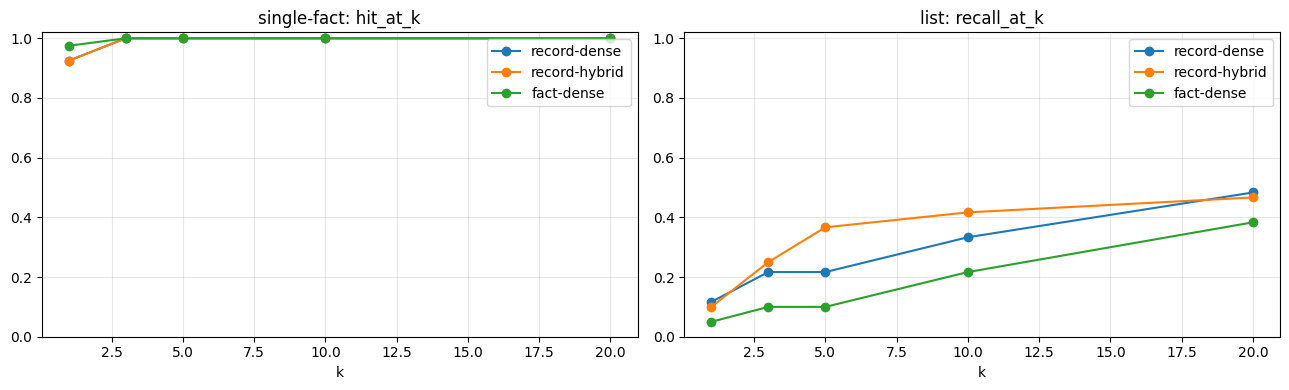

hit_at_k                     recall_at_k        \
k                               1    3    5    10   20          1     3    
set         retriever                                                      
list        fact-dense        0.20  0.2  0.2  0.4  0.8        0.05  0.10   
            record-dense      0.40  0.6  0.6  1.0  1.0        0.12  0.22   
            record-hybrid     0.40  0.6  0.8  0.8  0.8        0.10  0.25   
single-fact fact-dense        0.98  1.0  1.0  1.0  1.0        0.98  1.00   
            record-dense      0.92  1.0  1.0  1.0  1.0        0.92  1.00   
            record-hybrid     0.92  1.0  1.0  1.0  1.0        0.92  1.00   

                                             
k                            5     10    20  
set         retriever                        
list        fact-dense     0.10  0.22  0.38  
            record-dense   0.22  0.33  0.48  
            record-hybrid  0.37  0.42  0.47  
single-fact fact-dense     1.00  1.00  1.00  
            record-dense   1.00  1.00  1.00  
            record-hybrid  1.00  1.00  1.00

In [10]:
# ---- top-k sweep ---------------------------------------------------------------------------------------------------------------------------------------------------------------------------
def norm_text(s):
    s = re.sub(r"(?<=\d)[.,](?=\d{3}(?!\d))", "", str(s)); s = re.sub(r"[^a-z0-9]+", " ", s.lower()); s = re.sub(r"(\d)([a-z])", r"\1 \2", s); return re.sub(r"\s+", " ", s).strip()
def contains_key(text, key):
    nk = norm_text(key); return bool(nk) and re.search(r"(?<![a-z0-9])" + re.escape(nk) + r"(?![a-z0-9])", norm_text(text)) is not None

rng = np.random.default_rng(SEED)
single = []
for r in recs:
    for u, p in r["prices"]:
        if sum(1 for uu, _ in r["prices"] if uu == u) == 1: single.append((f"What is the price of '{r['name']}' per {u}?", [str(p)]))
    single.append((f"Which disease category does '{r['name']}' belong to?", [r["category"]]))
single = [single[i] for i in rng.permutation(len(single))[:40]]
eff_names = defaultdict(list)
for r in recs:
    for t in r["effect_terms"]: eff_names[t].append(r["name"])
terms = [t for t, v in eff_names.items() if 3 <= len(v) <= 10] or [t for t, v in sorted(eff_names.items(), key=lambda x: len(x[1]))[:6]]
lists = [(f"Which drugs list {t} as a side effect?", sorted(eff_names[t])) for t in terms[:20]]

RETRIEVERS = {"record-dense": (Rrec, "dense"), "record-hybrid": (Rrec, "hybrid"), "fact-dense": (Rfact, "dense")}
KS, rows = [1, 3, 5, 10, 20], []
for name, qs in (("single-fact", single), ("list", lists)):
    for rname, (retr, mode) in RETRIEVERS.items():
        for k in KS:
            hit, rec = [], []
            for qn, keys in qs:
                blob = " ".join(i["text"] for i in retr.retrieve(qn, k=k, mode=mode)["items"])
                hit.append(float(any(contains_key(blob, x) for x in keys))); rec.append(float(np.mean([contains_key(blob, x) for x in keys])))
            rows.append(dict(set=name, retriever=rname, k=k, hit_at_k=np.mean(hit), recall_at_k=np.mean(rec), n=len(qs)))
sweep = pd.DataFrame(rows); sweep.to_csv(f"{OUT}/topk_sweep.csv", index=False)
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, metric) in zip(axs, (("single-fact", "hit_at_k"), ("list", "recall_at_k"))):
    for rname in RETRIEVERS:
        s = sweep[(sweep.set == name) & (sweep.retriever == rname)]; ax.plot(s.k, s[metric], marker="o", label=rname)
    ax.set_title(f"{name}: {metric}"); ax.set_xlabel("k"); ax.set_ylim(0, 1.02); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/topk_sweep.png", dpi=130); plt.show()
sweep.pivot_table(index=["set", "retriever"], columns="k", values=["hit_at_k", "recall_at_k"]).round(2)

In [11]:
# ---- embedding-model ablation (in-memory indexes; Hit@5 single-fact, Recall@5 list) -----------------------------------------------------------------------------------------
def eval_model(name, prefix):
    emb = SentenceTransformer(name, device=DEVICE)
    cl = chromadb.EphemeralClient(); ids_, docs_, metas_ = vr.build_record_docs(recs)
    col, t = vr.build_collection(cl, "tmp_" + re.sub(r"\W", "_", name)[:40], ids_, docs_, metas_, emb)
    res = {}
    for nm, qs in (("single-fact", single), ("list", lists)):
        sc = []
        for qn, keys in qs:
            e = emb.encode([prefix + qn], normalize_embeddings=True)[0].tolist()
            txt = " ".join(col.query(query_embeddings=[e], n_results=5)["documents"][0])
            sc.append(np.mean([contains_key(txt, x) for x in keys]) if nm == "list" else float(any(contains_key(txt, x) for x in keys)))
        res[nm] = float(np.mean(sc))
    return {"model": name, "dim": emb.get_sentence_embedding_dimension(), "index_s": round(t, 2), **res}
abl = [eval_model(EMB_MODEL, vr.QUERY_PREFIX)] + [eval_model(m, vr.QUERY_PREFIX if "bge" in m else "") for m in COMPARE_EMBEDDERS]
abl = pd.DataFrame(abl).rename(columns={"single-fact": "Hit@5 single-fact", "list": "Recall@5 list"}); abl.to_csv(f"{OUT}/embedding_ablation.csv", index=False); abl

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (18 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,model,dim,index_s,Hit@5 single-fact,Recall@5 list
0,BAAI/bge-small-en-v1.5,384,1.16,1.000,0.216667
1,sentence-transformers/all-MiniLM-L6-v2,384,0.51,0.925,0.316667
2,BAAI/bge-base-en-v1.5,768,3.02,1.000,0.266667


In [12]:
# ---- save artefacts ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
BUILD.update(lines_of_pipeline_code=sum(len(open(f).read().splitlines()) for f in ("rag_common.py", "vector_rag.py")),
             generator=GEN_MODEL, k_eval=K_EVAL, k_context=K_CONTEXT)
json.dump(BUILD, open(f"{OUT}/build_costs_vector.json", "w"), indent=2)
print(json.dumps(BUILD, indent=2))
print("rag_common.py md5:", hashlib.md5(open("rag_common.py", "rb").read()).hexdigest(), "(must equal the copy from notebook 1)")
print(sorted(os.listdir(OUT)))

{
  "embedding_model": "BAAI/bge-small-en-v1.5",
  "index_record_s": 2.12,
  "n_record_chunks": 112,
  "index_fact_s": 1.74,
  "n_fact_chunks": 763,
  "lines_of_pipeline_code": 307,
  "generator": "qwen2.5:7b-instruct",
  "k_eval": 5,
  "k_context": 10
}
rag_common.py md5: 4608258e60335def4a5e3c5d704fc9dd (must equal the copy from notebook 1)
['__notebook__.ipynb', '__pycache__', 'build_costs_vector.json', 'chroma_db', 'embedding_ablation.csv', 'figures', 'ollama.log', 'rag_common.py', 'topk_sweep.csv', 'vector_rag.py']


## Summary for the report
* **Design table** with the evidence from Section 6 (`topk_sweep.csv`, `embedding_ablation.csv`): record- vs fact-level chunks, dense vs hybrid, k.
* **Build cost:** indexing time for both indexes and lines of code (`build_costs_vector.json`).
* **Observation to carry into Notebook 3:** the list-question recall curve (how many records are needed vs what fits in k).

**Next:** *Notebook 3 — Evaluation and Comparison* (add the outputs of notebooks 1 **and** 2 as inputs).